![Banner](../images/03_08_banner_spatial_analysis_capstone.png)


# Watershed Characterization of the Onondaga Lake Watershed



This is Capstone 2 of the spatial analysis module (Part 7). It applies the DEM, flow-routing and terrain tools from 03.02 to one basin, the Onondaga Lake watershed in central New York, and turns the rasters into morphometric numbers that can be compared across sub-basins.

**Data:** `Data/00_shared/raster_data/USA/Onondaga_DEM.tif` (about 92 m by 126 m cells) and the county boundary `Data/00_shared/vector_data/USA/NY_County_PROJ.shp`.

**Study area:** Onondaga Lake watershed, about 738 km².

**Library:** `geolattice.spatial_analysis`

## Overview

A watershed characterization describes how a drainage basin is built: where its boundary runs, how its stream network is organised, how steep and how wet its terrain is, and which parts of it respond fastest to rainfall. Planners use it as the first step before flood studies, erosion control, or water-quality work.

This capstone applies the terrain and hydrology tools from Module **03.02** to one real basin, the **Onondaga Lake watershed** in central New York, and adds the morphometric analysis that turns raster outputs into numbers a watershed manager can compare across sub-basins.

## Overview

| Stage | Question | Main tools |
|---|---|---|
| **Prepare** | Is the DEM fit for flow routing? | `reproject_raster`, `fill_depressions` |
| **Route** | Where does water go and where does it concentrate? | `d8_pointer`, `d8_flow_accumulation`, `dinf_flow_accumulation` |
| **Delineate** | What drains to the lake and to each gauge? | `extract_streams`, `snap_pour_points`, `watershed` |
| **Validate** | Do delineated areas match published drainage areas? | comparison table |
| **Measure** | What is the shape, relief and drainage texture of each sub-basin? | morphometric indices, `strahler_order` (helper) |
| **Describe** | How steep, how wet, how fast? | `slope`, `wetness_index`, `landform_classification`, `elevation_above_stream`, Kirpich time of concentration |
| **Prioritise** | Which sub-basins deserve attention first? | compound ranking and its sensitivity |

### What this notebook reuses

| Topic | Notebook |
|---|---|
| DEM preprocessing | [`03_02_01_dem_preprocessing.ipynb`](../03_02_digital_terrain_modeling/03_02_01_dem_preprocessing.ipynb) |
| Slope, curvature, landforms | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |
| Flow routing, streams, watersheds | [`03_02_03_hydrology_modeling.ipynb`](../03_02_digital_terrain_modeling/03_02_03_hydrology_modeling.ipynb) |
| Zonal summaries | [`03_01_03_raster_analysis.ipynb`](../03_01_foundation/03_01_03_raster_analysis.ipynb) |

The hydrology layers written here (conditioned DEM, flow direction, flow accumulation, streams, height above stream) are reused by the flood capstone, `03_07_01_flood_susceptibility_mapping.ipynb`.

## Table of Contents

1. [Setup](#setup)
2. [Problem statement and study area](#problem-statement-and-study-area)
3. [DEM preparation and conditioning](#dem-preparation-and-conditioning)
4. [Flow direction and flow accumulation](#flow-direction-and-flow-accumulation)
5. [Stream network and threshold sensitivity](#stream-network-and-threshold-sensitivity)
6. [Watershed delineation and validation](#watershed-delineation-and-validation)
7. [Sub-basins](#sub-basins)
8. [Morphometric analysis](#morphometric-analysis)
9. [Hypsometric analysis](#hypsometric-analysis)
10. [Terrain and wetness by sub-basin](#terrain-and-wetness-by-sub-basin)
11. [Hydrologic response](#hydrologic-response)
12. [Land cover and soils (optional external data)](#land-cover-and-soils-optional-external-data)
13. [Sub-basin prioritisation](#sub-basin-prioritisation)
14. [Outputs and watershed report card](#outputs-and-watershed-report-card)
15. [Limitations](#limitations)
16. [Where to go next](#where-to-go-next)

## Setup

Locate the repository root, import the GeoLattice tools and the shared capstone helpers in `data_processing.py`, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports.
import sys  # make the capstone helper module importable
import warnings  # silence harmless runtime warnings from empty slices
from pathlib import Path  # filesystem paths

# Third-party numeric / geospatial / plotting stack.
import geopandas as gpd  # sub-basin polygons and the output GeoPackage
import matplotlib.pyplot as plt  # maps and charts
import numpy as np  # raster arrays
import pandas as pd  # morphometric tables
from IPython.display import display  # rich table previews
from pyproj import Transformer  # gauge longitude / latitude -> UTM

# Shared capstone helpers live next to this notebook.
sys.path.insert(0, str(Path.cwd()))
import data_processing as dp  # paths, raster I/O, drainage-network helpers

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    ROOT = dp.find_repo_root()

# Raster helpers.
from geolattice.raster import (
    polygonize,  # raster zones -> polygons
    summarize_raster,  # quick raster statistics
)

# Terrain and surface-hydrology tools from Module 03.02.
from geolattice.spatial_analysis import (
    d8_flow_accumulation,  # upslope cell count
    d8_pointer,  # D8 flow direction codes
    dinf_flow_accumulation,  # D-infinity specific catchment area
    elevation_above_stream,  # height above nearest drainage (HAND)
    extract_streams,  # threshold accumulation into channels
    fill_depressions,  # Priority-Flood depression filling with flat resolution
    hillshade,  # shaded relief backdrop
    landform_classification,  # TPI-based landform classes
    slope,  # slope in degrees
    snap_pour_points,  # move outlets onto the channel
    watershed,  # upslope area of each outlet
    wetness_index,  # topographic wetness index
)
from geolattice.viz import apply_map_style, plot_raster

apply_map_style()  # GeoLattice tutorial map defaults
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 2)

# Output folder for every layer written by this notebook.
OUT = dp.capstone_dir(ROOT, "onondaga") / "watershed"
OUT.mkdir(parents=True, exist_ok=True)

print(f"Repository root: {ROOT}")
print(f"Outputs:         {OUT}")

Repository root: /home/zia207/Github/GeoLattice
Outputs:         /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/capstone_spatial_analysis/onondaga/watershed


## Problem statement and study area

**Onondaga Lake** lies on the north side of Syracuse, New York. Its watershed of roughly 738 km² sits almost entirely inside Onondaga County and spans two very different landscapes:

- the **Appalachian Plateau** in the south, with relief of several hundred metres and deep, glacially carved "through valleys" such as the Tully Valley;
- the **Ontario Lake Plain** in the north, a low, nearly flat surface that carries the city of Syracuse.

Two tributaries, **Onondaga Creek** and **Ninemile Creek**, deliver most of the inflow. **Ley Creek** and **Harbor Brook** drain the urban area.

**Question.** What are the physical and hydrologic characteristics of the Onondaga Lake watershed and its sub-basins, and which sub-basins should be looked at first for runoff and erosion management?

**Data.** Only one input is needed for the core analysis:

| Layer | File | Notes |
|---|---|---|
| Elevation | `Data/00_shared/raster_data/USA/Onondaga_DEM.tif` | Clipped to the county, geographic coordinates, about 92 m x 126 m cells |
| County boundary | `Data/00_shared/vector_data/USA/NY_County_PROJ.shp` | Map context |

Land cover and soil layers are optional and handled in Section 12.

Grid:        501 x 564 cells at 100 m, EPSG:26918
Data area:   2,094 km2
Elevation:   108 to 622 m


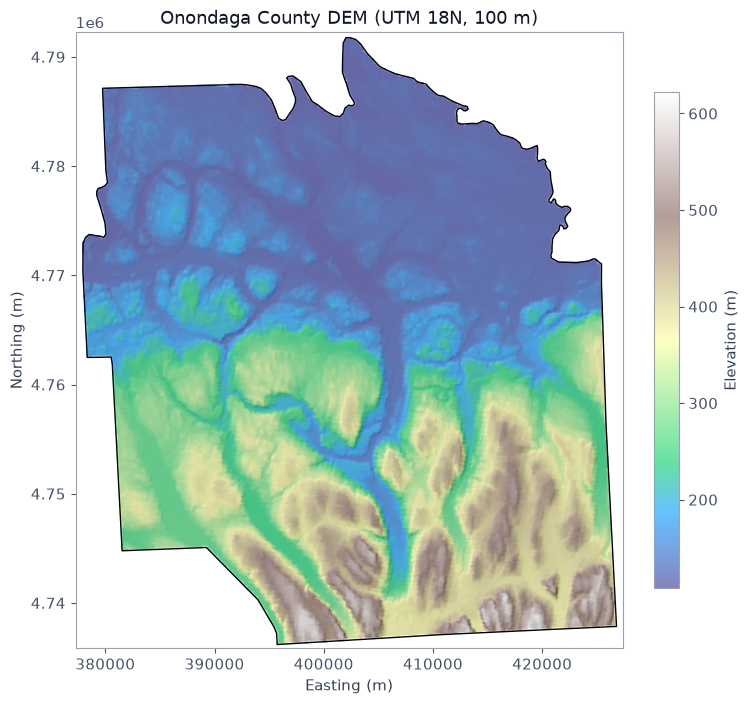

In [2]:
# Project the county DEM to UTM 18N on a 100 m grid (cached after the first run).
DEM = dp.prepare_onondaga_dem(ROOT, resolution=100.0)

dem, GT, CRS = dp.read_band(DEM)  # elevation array, geotransform, CRS
CELL = abs(GT[1])  # cell size in metres
CELL_KM2 = CELL * CELL / 1e6  # cell area in km2
EXTENT = dp.extent_of(DEM)  # imshow extent for every map below
valid = np.isfinite(dem)  # cells inside the county

print(f"Grid:        {dem.shape[1]} x {dem.shape[0]} cells at {CELL:.0f} m, {CRS}")
print(f"Data area:   {valid.sum() * CELL_KM2:,.0f} km2")
print(f"Elevation:   {np.nanmin(dem):.0f} to {np.nanmax(dem):.0f} m")

# Hillshade backdrop used under most maps.
HS = OUT / "hillshade.tif"
hillshade(DEM, HS, azimuth=315, altitude=45, overwrite=True)
hs, _, _ = dp.read_band(HS)

# Onondaga County outline in the DEM's CRS.
county = gpd.read_file(ROOT / "Data" / "00_shared" / "vector_data" / "USA" / "NY_County_PROJ.shp")
name_col = "COUNTY" if "COUNTY" in county.columns else county.columns[0]
county = county[county[name_col].astype(str).str.contains("Onondaga", case=False)].to_crs(dp.ONONDAGA_CRS)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(hs, cmap="gray", extent=EXTENT)
im = ax.imshow(dem, cmap="terrain", extent=EXTENT, alpha=0.6)
county.boundary.plot(ax=ax, color="black", linewidth=1)
plt.colorbar(im, ax=ax, fraction=0.04, label="Elevation (m)")
ax.set_title("Onondaga County DEM (UTM 18N, 100 m)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.show()

## DEM preparation and conditioning

Flow routing needs a surface on which every cell has a lower neighbour until the water leaves the map. Two properties of this DEM need care:

1. **It is clipped to the county.** The data are bounded by nodata, not by the edge of the raster, so water must be allowed to leave through any valid cell that touches nodata.
2. **It contains large flats.** Onondaga Lake, Otisco Lake and the valley floors are level in the DEM. A flat has no downslope neighbour, so flow stops there unless a small gradient is imposed.

`fill_depressions` with `fix_flats=True` handles both with **Priority-Flood + epsilon** (Barnes, Lehman and Mulla, 2014). The flood starts from every cell on the data boundary and moves inward in order of elevation. A cell that is not higher than the cell it was reached from is raised by the smallest representable increment, which fills depressions and drains flats in one pass.

,value
cells,209414.00
cells raised by more than 0.1 m,12833.00
share of cells raised (%),6.13
maximum fill (m),15.98
mean fill where raised (m),1.74


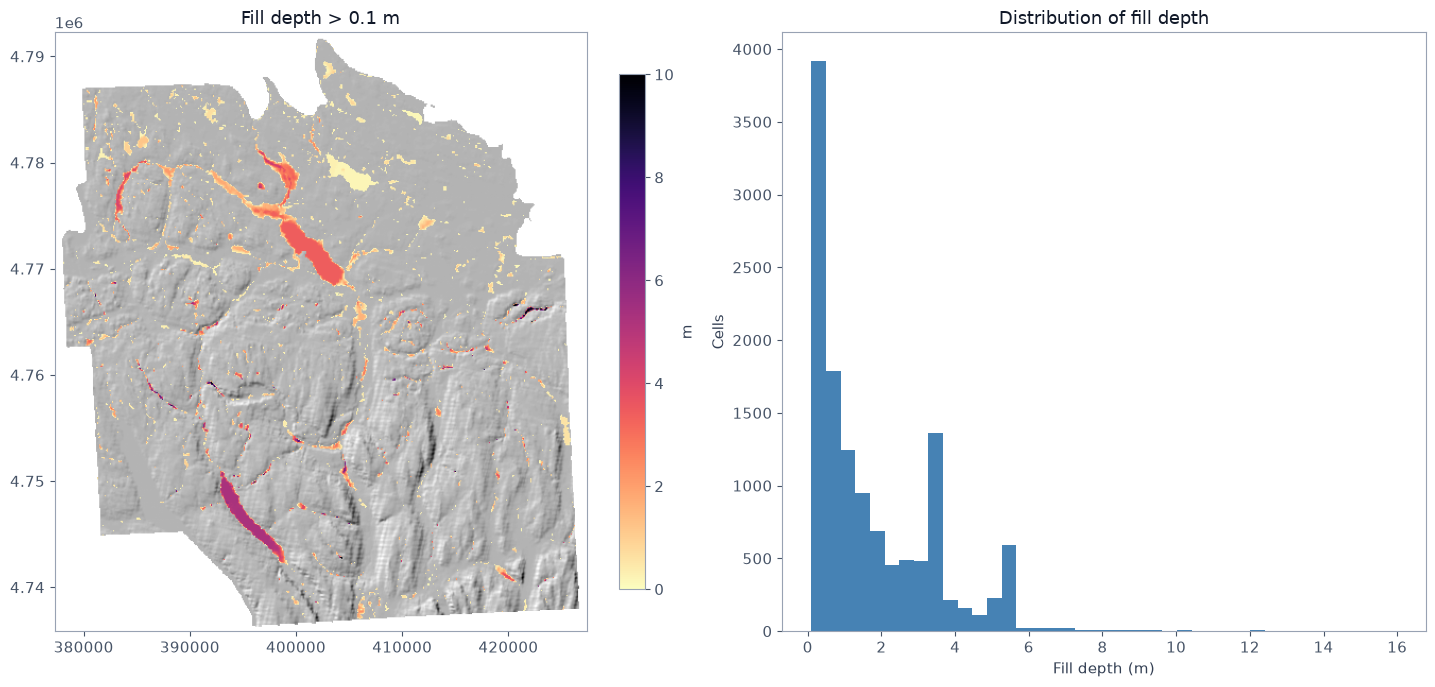

In [3]:
# Condition the DEM and report what changed.
DEM_COND = OUT / "dem_conditioned.tif"
fill_depressions(DEM, DEM_COND, fix_flats=True, overwrite=True)

cond, _, _ = dp.read_band(DEM_COND)
fill_depth = cond - dem  # metres added by conditioning
raised = fill_depth > 0.1  # ignore the epsilon-only changes
diag = pd.Series(
    {
        "cells": int(valid.sum()),
        "cells raised by more than 0.1 m": int(raised.sum()),
        "share of cells raised (%)": 100 * raised.sum() / valid.sum(),
        "maximum fill (m)": float(np.nanmax(fill_depth)),
        "mean fill where raised (m)": float(np.nanmean(fill_depth[raised])),
    }
)
display(diag.to_frame("value"))
fill_show = np.where(fill_depth > 0.1, fill_depth, np.nan)  # hide the epsilon-only changes

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(hs, cmap="gray", extent=EXTENT)
im0 = axes[0].imshow(fill_show, cmap="magma_r", extent=EXTENT, vmin=0, vmax=10)
axes[0].set_title("Fill depth > 0.1 m")
plt.colorbar(im0, ax=axes[0], fraction=0.04, label="m")
axes[1].hist(fill_depth[fill_depth > 0.1], bins=40, color="steelblue")
axes[1].set_xlabel("Fill depth (m)")
axes[1].set_ylabel("Cells")
axes[1].set_title("Distribution of fill depth")
plt.tight_layout()
plt.show()

**Reading the result.** About six percent of the cells are raised by more than 0.1 m. They sit in closed depressions on the plateau, in kettle holes on the valley floors and in quarries near Syracuse. Fill depths of several metres on a 100 m DEM usually mean a real feature (a reservoir, a quarry, a road embankment that blocks a valley), not noise. For a design study each large fill would be checked against imagery.

## Flow direction and flow accumulation

**D8** sends all flow from a cell to its steepest downslope neighbour. It gives clean, single-thread channels and is the standard for delineation. **D-infinity** splits flow between two neighbours according to the true downslope angle, which represents dispersion on hillslopes better. We route with both, use D8 for the network and basins, and use D-infinity for the wetness index.

Cells without a flow direction: 476 (all on the county boundary: outlets)
Largest contributing area:      953 km2


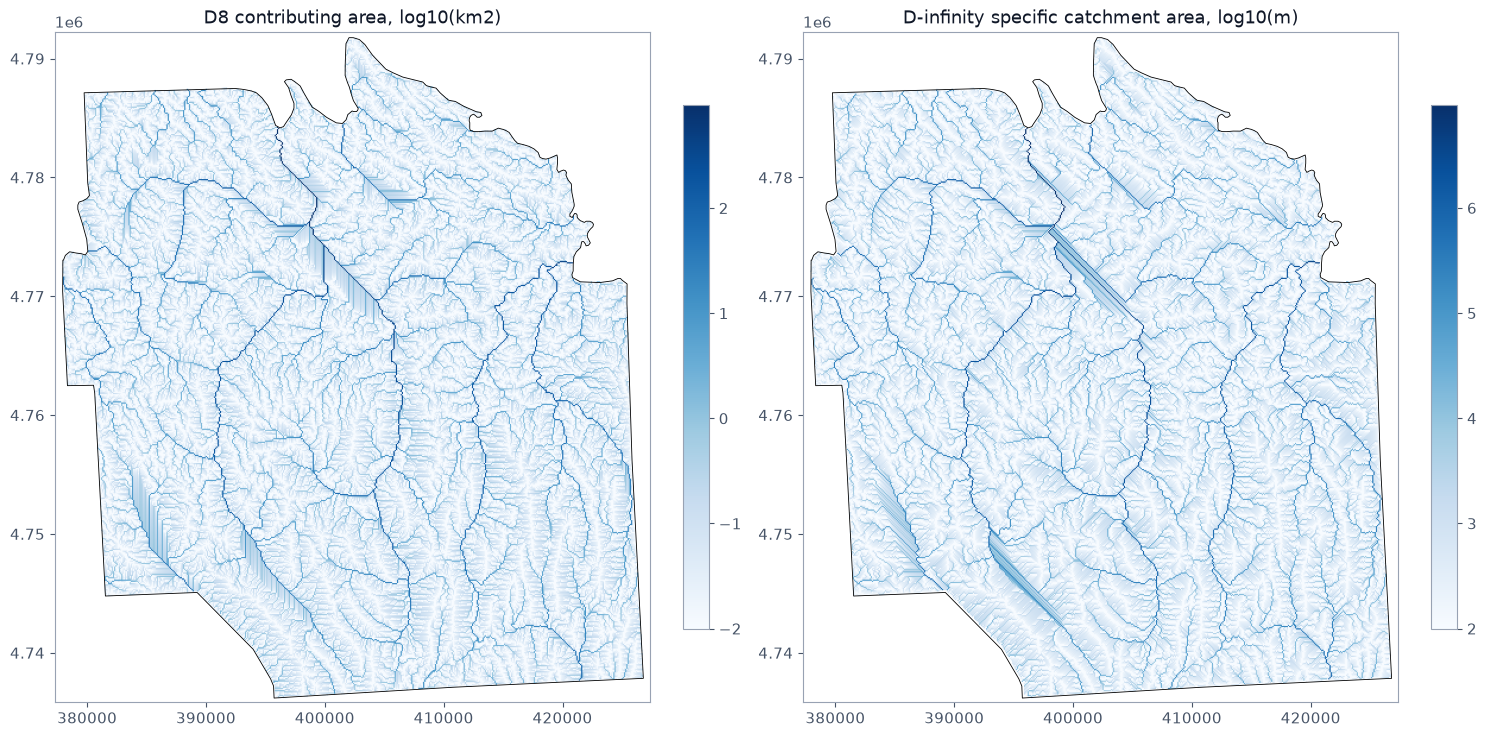

In [4]:
# D8 pointer and accumulation from the conditioned DEM.
D8 = OUT / "d8_pointer.tif"
FA = OUT / "d8_flow_accumulation.tif"
d8_pointer(DEM_COND, D8, overwrite=True)
d8_flow_accumulation(DEM_COND, FA, out_type="cells", pointer=D8, overwrite=True)

# D-infinity specific catchment area for comparison.
SCA = OUT / "dinf_sca.tif"
dinf_flow_accumulation(DEM_COND, SCA, out_type="sca", overwrite=True)

fa, _, _ = dp.read_band(FA)
sca, _, _ = dp.read_band(SCA)
ptr, _, _ = dp.read_band(D8)

# Cells with no flow direction should only be outlets on the data boundary.
no_dir = valid & ~np.isfinite(ptr)
print(f"Cells without a flow direction: {no_dir.sum()} (all on the county boundary: outlets)")
print(f"Largest contributing area:      {np.nanmax(fa) * CELL_KM2:,.0f} km2")

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, arr, title in zip(
    axes,
    [np.log10(np.maximum(fa * CELL_KM2, CELL_KM2)), np.log10(np.maximum(sca, 1.0))],
    ["D8 contributing area, log10(km2)", "D-infinity specific catchment area, log10(m)"],
):
    im = ax.imshow(arr, cmap="Blues", extent=EXTENT)
    county.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

The D8 map shows the organised network: Onondaga Creek running north through the Tully Valley, Ninemile Creek leaving Otisco Lake in the south-west, and the Seneca and Oneida rivers collecting flow across the lake plain. The D-infinity surface is smoother on hillslopes, which is why it is preferred for the wetness index in Section 10.

## Stream network and threshold sensitivity

A cell is called a stream when its contributing area exceeds a threshold. The threshold is a modelling choice: a small value draws channels up every hollow, a large value keeps only the main rivers. Drainage density, one of the key morphometric indices, depends directly on it, so the choice must be reported.

$$
D_d = \frac{\sum L_{stream}}{A}
$$

,threshold_km2,stream_cells,length_km,drainage_density_km_per_km2
0,0.25,26597,3005.28,1.44
1,0.50,17676,2014.51,0.96
2,1.00,12151,1394.36,0.67
3,2.00,8304,957.74,0.46
4,5.00,5066,590.37,0.28
5,10.00,3511,411.35,0.20


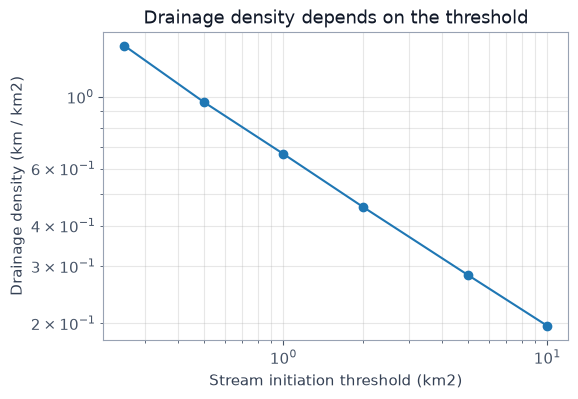

In [5]:
# Drainage density of the whole data area for a range of thresholds.
recv, step = dp.d8_receivers(ptr)  # downstream cell and step length for every cell
step_km = step.reshape(dem.shape) * CELL / 1000.0  # channel length carried by each cell (km)

rows_ = []
for thr_km2 in [0.25, 0.5, 1.0, 2.0, 5.0, 10.0]:
    mask = fa * CELL_KM2 >= thr_km2
    length = np.nansum(step_km[mask])
    rows_.append({"threshold_km2": thr_km2, "stream_cells": int(mask.sum()), "length_km": length,
                  "drainage_density_km_per_km2": length / (valid.sum() * CELL_KM2)})
thr_table = pd.DataFrame(rows_)
display(thr_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(thr_table["threshold_km2"], thr_table["drainage_density_km_per_km2"], "o-")
ax.set_xlabel("Stream initiation threshold (km2)")
ax.set_ylabel("Drainage density (km / km2)")
ax.set_title("Drainage density depends on the threshold")
ax.grid(True, which="both", alpha=0.3)
plt.show()

Drainage density falls steadily as the threshold rises, with no natural break. We adopt **1 km²** (100 cells): it is the smallest area at which a 100 m DEM can resolve a valley, and it is a common choice for regional studies. Every index that uses stream length below carries this assumption.

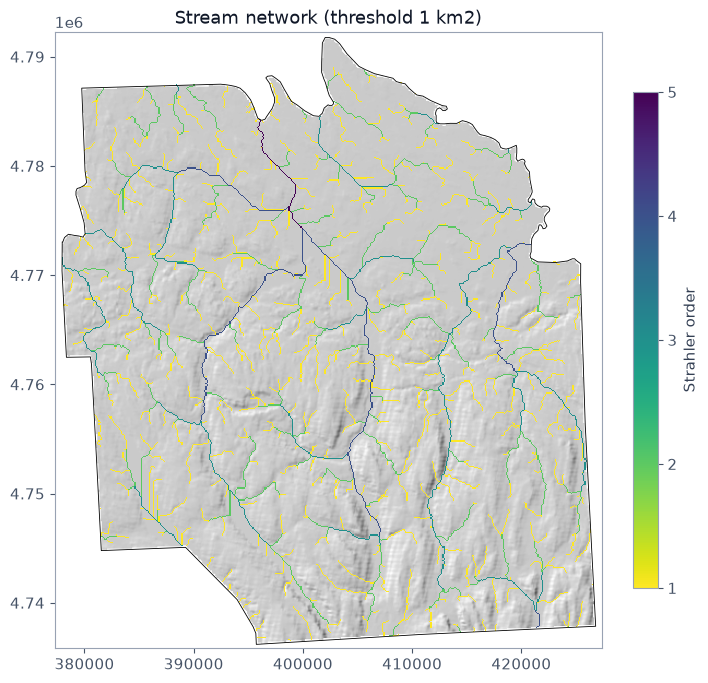

In [6]:
STREAM_THRESHOLD_KM2 = 1.0
STREAMS = OUT / "streams.tif"
extract_streams(FA, STREAMS, threshold=STREAM_THRESHOLD_KM2 / CELL_KM2, overwrite=True)

# Strahler order of every stream cell (helper; see data_processing.py).
ORDER = OUT / "strahler_order.tif"
dp.strahler_order(STREAMS, D8, DEM_COND, ORDER)
order, _, _ = dp.read_band(ORDER)
streams = np.isfinite(order)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(hs, cmap="gray", extent=EXTENT, alpha=0.7)
im = ax.imshow(np.where(streams, order, np.nan), cmap="viridis_r", extent=EXTENT, interpolation="nearest")
county.boundary.plot(ax=ax, color="black", linewidth=0.6)
plt.colorbar(im, ax=ax, fraction=0.04, ticks=range(1, int(np.nanmax(order)) + 1), label="Strahler order")
ax.set_title(f"Stream network (threshold {STREAM_THRESHOLD_KM2:g} km2)")
plt.show()

## Watershed delineation and validation

A delineation is only as good as its outlets. We use five: the outlet of Onondaga Lake and four stream gauges on its tributaries. Gauge coordinates are approximate, so each point is **snapped** to the stream cell with the largest contributing area within a search distance.

Published drainage areas give an independent check:

| Outlet | Published area (km²) | Source |
|---|---|---|
| Onondaga Creek at Spencer Street (USGS 04240010) | 284.9 | USGS gauge record |
| Ninemile Creek at Lakeland (USGS 04240300) | 297.8 | USGS gauge record |
| Ley Creek at Park Street (USGS 04240120) | 66.1 | Onondaga County Ambient Monitoring Program |
| Harbor Brook at Hiawatha Boulevard (USGS 04240105) | 31.4 | Onondaga County Ambient Monitoring Program |
| Onondaga Lake outlet | 738 | Onondaga Environmental Institute |

In [7]:
# Outlets: name, longitude, latitude, published area (km2), snap distance (m).
# Coordinates other than Spencer Street are approximate and rely on snapping.
outlets = pd.DataFrame(
    [
        ("Onondaga Creek at Spencer St", -76.1620, 43.0574, 284.9, 600),
        ("Ninemile Creek at Lakeland", -76.2264, 43.0806, 297.8, 600),
        ("Ley Creek at Park St", -76.1697, 43.0775, 66.1, 600),
        ("Harbor Brook at Hiawatha Blvd", -76.1836, 43.0564, 31.4, 600),
        ("Onondaga Lake outlet", -76.2478, 43.1178, 738.0, 1000),
    ],
    columns=["outlet", "lon", "lat", "published_km2", "snap_m"],
)

to_utm = Transformer.from_crs("EPSG:4326", dp.ONONDAGA_CRS, always_xy=True)
outlets["x"], outlets["y"] = to_utm.transform(outlets["lon"].values, outlets["lat"].values)

# Snap each outlet to the largest stream within its search distance.
snapped = []
for _, o in outlets.iterrows():
    sx, sy = snap_pour_points([(o.x, o.y)], STREAMS, snap_distance=float(o.snap_m), prefer_flow_accumulation=FA)[0]
    snapped.append((sx, sy))
outlets["x_snap"] = [s[0] for s in snapped]
outlets["y_snap"] = [s[1] for s in snapped]
outlets["moved_m"] = np.hypot(outlets.x_snap - outlets.x, outlets.y_snap - outlets.y)

# Delineated area = flow accumulation at the snapped cell.
rc = [dp.xy_to_rowcol(x, y, GT) for x, y in snapped]
outlets["delineated_km2"] = [fa[r, c] * CELL_KM2 for r, c in rc]
outlets["difference_pct"] = 100 * (outlets.delineated_km2 - outlets.published_km2) / outlets.published_km2
display(outlets[["outlet", "published_km2", "delineated_km2", "difference_pct", "moved_m"]])

,outlet,published_km2,delineated_km2,difference_pct,moved_m
0,Onondaga Creek at Spencer St,284.9,322.57,13.22,444.91
1,Ninemile Creek at Lakeland,297.8,287.73,-3.38,518.05
2,Ley Creek at Park St,66.1,76.24,15.34,515.69
3,Harbor Brook at Hiawatha Blvd,31.4,2.55,-91.88,568.90
4,Onondaga Lake outlet,738.0,735.88,-0.29,929.37


**Reading the validation table.**

- The **lake outlet** and **Ninemile Creek** agree with the published areas to within a few percent. Their divides run along plateau ridges that a 100 m DEM resolves well.
- **Onondaga Creek** and **Ley Creek** are over-estimated by roughly 13 to 15 percent.
- **Harbor Brook** is not recovered: the snapped outlet drains under 3 km² against a published 31 km². The basin is small, narrow and largely urban, and its lower course runs through culverts. On this DEM most of its area is routed to a neighbouring stream, which is a likely contributor to the Onondaga Creek surplus. The gauge coordinates used here are approximate, which adds to the uncertainty for an outlet this small.

The lesson is general: a coarse DEM delineates large, high-relief basins well and small, low-relief or engineered basins poorly. Where storm sewers or culverts control drainage, the terrain surface is no longer the right model, and a finer DEM with a burned-in drainage network is required.

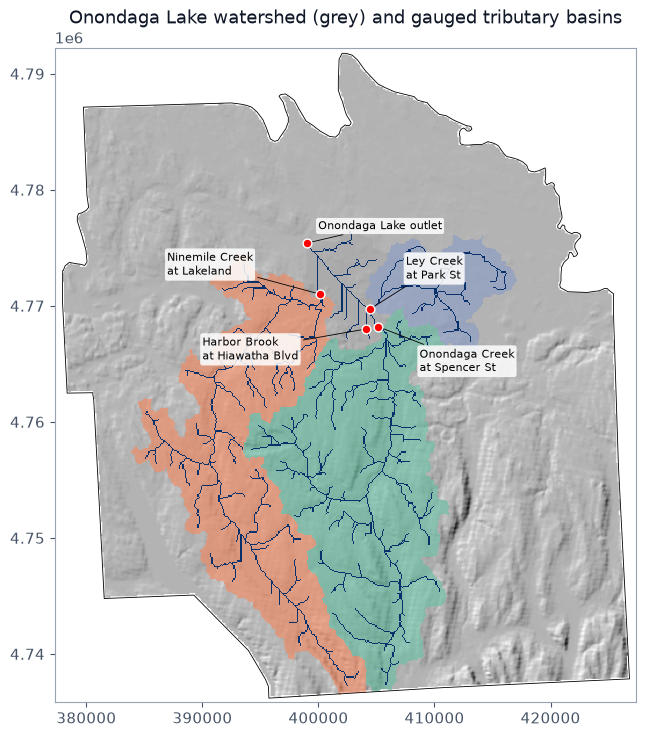

Onondaga Lake watershed: 735.9 km2


In [8]:
# Delineate the lake watershed and the gauged tributary basins.
lake_xy = snapped[-1]
WS = OUT / "watershed_lake.tif"
watershed(D8, [lake_xy], WS, overwrite=True)
ws, _, _ = dp.read_band(WS)
in_ws = np.isfinite(ws)  # True inside the Onondaga Lake watershed

GAUGE_WS = OUT / "watersheds_gauges.tif"
watershed(D8, snapped[:3], GAUGE_WS, overwrite=True)  # Harbor Brook omitted (not resolved)
gws, _, _ = dp.read_band(GAUGE_WS)

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(hs, cmap="gray", extent=EXTENT)
ax.imshow(np.where(in_ws, 1.0, np.nan), cmap="Greys", extent=EXTENT, alpha=0.25, vmin=0, vmax=2)
im = ax.imshow(gws, cmap="Set2", extent=EXTENT, alpha=0.6, interpolation="nearest", vmin=1, vmax=8)
ax.imshow(np.where(streams & in_ws, 1.0, np.nan), cmap="Blues", extent=EXTENT, vmin=0, vmax=1, interpolation="nearest")
ax.scatter(outlets.x_snap, outlets.y_snap, c="red", s=40, zorder=5, edgecolor="white")
label_offsets = [(30, -32), (-110, 14), (26, 22), (-118, -22), (8, 10)]  # keep the labels apart
for (_, o), off in zip(outlets.iterrows(), label_offsets):
    ax.annotate(o.outlet.replace(" at ", "\nat "), (o.x_snap, o.y_snap), xytext=off, textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="-", color="black", lw=0.6),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.85, lw=0))
county.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_title("Onondaga Lake watershed (grey) and gauged tributary basins")
plt.show()

print(f"Onondaga Lake watershed: {in_ws.sum() * CELL_KM2:,.1f} km2")

## Sub-basins

Management decisions are made for parts of a watershed, so the basin is split into sub-basins. `dp.subbasin_outlets` places an outlet at the end of every branch that drains at least **25 km²** where it meets another such branch. `watershed` then labels the area above each outlet. The result is one unit per major tributary plus the inter-basin areas along the main stems.

Sub-basins: 13 delineated, 12 of at least 5 km2 kept for analysis
Area covered by the analysed units: 99.5%


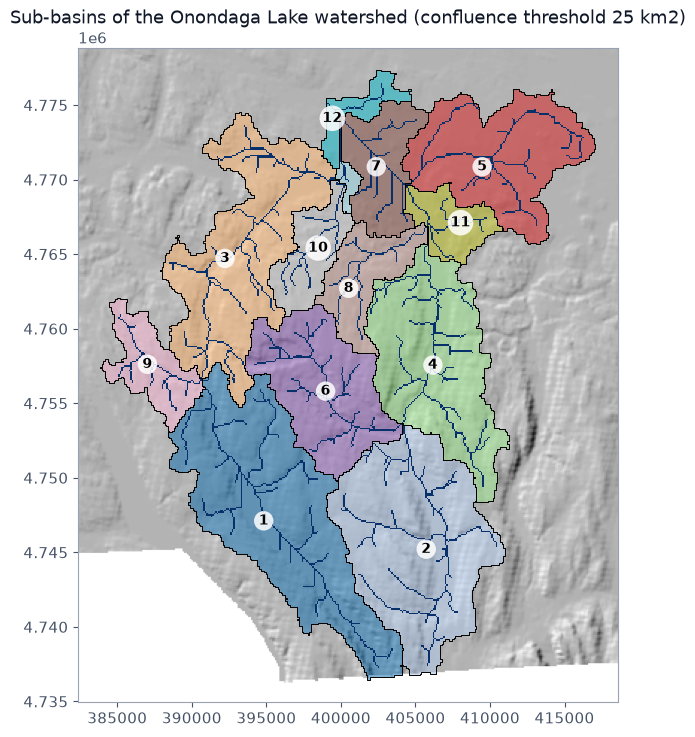

In [9]:
SUB_THRESHOLD_KM2 = 25.0
sub_xy = dp.subbasin_outlets(FA, D8, threshold_cells=SUB_THRESHOLD_KM2 / CELL_KM2, mask=in_ws)
sub_xy = sub_xy + [lake_xy]  # the lake outlet closes the last unit

SUB = OUT / "subbasins_raw.tif"
watershed(D8, sub_xy, SUB, overwrite=True)
sub_raw, _, _ = dp.read_band(SUB)
sub_raw[~in_ws] = np.nan

# Renumber from largest to smallest and keep units of at least 5 km2 for analysis.
ids, counts = np.unique(sub_raw[np.isfinite(sub_raw)], return_counts=True)
order_by_area = ids[np.argsort(-counts)]
sub = np.full(sub_raw.shape, np.nan)
outlet_of = {}  # new id -> outlet (x, y)
for new_id, old_id in enumerate(order_by_area, start=1):
    sub[sub_raw == old_id] = new_id
    outlet_of[new_id] = sub_xy[int(old_id) - 1]
SUBBASINS = OUT / "subbasins.tif"
dp.write_band(SUBBASINS, sub, DEM, nodata=0.0)

MIN_AREA_KM2 = 5.0
area_km2 = {i: float((sub == i).sum() * CELL_KM2) for i in outlet_of}
analysis_ids = [i for i in outlet_of if area_km2[i] >= MIN_AREA_KM2]
print(f"Sub-basins: {len(outlet_of)} delineated, {len(analysis_ids)} of at least {MIN_AREA_KM2:g} km2 kept for analysis")
print(f"Area covered by the analysed units: {sum(area_km2[i] for i in analysis_ids) / (in_ws.sum() * CELL_KM2):.1%}")

# Polygons for mapping, perimeter and the output GeoPackage.
SUB_GPKG_RAW = OUT / "subbasins_raw.gpkg"
polygonize(SUBBASINS, SUB_GPKG_RAW, field_name="sub_id", overwrite=True)
sub_gdf = gpd.read_file(SUB_GPKG_RAW)
sub_gdf = sub_gdf[sub_gdf["sub_id"] > 0].dissolve(by="sub_id").reset_index()
sub_gdf["sub_id"] = sub_gdf["sub_id"].astype(int)

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(hs, cmap="gray", extent=EXTENT)
ax.imshow(sub, cmap="tab20", extent=EXTENT, alpha=0.55, interpolation="nearest")
ax.imshow(np.where(streams & in_ws, 1.0, np.nan), cmap="Blues", extent=EXTENT, vmin=0, vmax=1, interpolation="nearest")
sub_gdf.boundary.plot(ax=ax, color="black", linewidth=0.7)
for _, row in sub_gdf[sub_gdf.sub_id.isin(analysis_ids)].iterrows():
    p = row.geometry.representative_point()
    ax.text(p.x, p.y, str(row.sub_id), ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="circle,pad=0.2", fc="white", alpha=0.85, lw=0))
xmin, ymin, xmax, ymax = sub_gdf.total_bounds
ax.set_xlim(xmin - 1500, xmax + 1500)
ax.set_ylim(ymin - 1500, ymax + 1500)
ax.set_title(f"Sub-basins of the Onondaga Lake watershed (confluence threshold {SUB_THRESHOLD_KM2:g} km2)")
plt.show()

## Morphometric analysis

Morphometry describes a basin with dimensionless or simply scaled numbers so that basins of different size can be compared. Three groups are computed for every sub-basin.

**Geometry (shape)**

| Index | Formula | Meaning |
|---|---|---|
| Form factor | $F_f = A / L_b^2$ | Low values: elongated basin, flatter and longer flood peak |
| Circularity ratio | $R_c = 4\pi A / P^2$ | 1 for a circle |
| Elongation ratio | $R_e = 2\sqrt{A/\pi} / L_b$ | Near 1: circular; below 0.7: elongated |
| Compactness coefficient | $C_c = P / (2\sqrt{\pi A})$ | 1 for a circle, larger for irregular outlines |

**Relief**

| Index | Formula | Meaning |
|---|---|---|
| Basin relief | $H = z_{max} - z_{min}$ | Potential energy of the basin |
| Relief ratio | $R_h = H / L_b$ | Overall steepness |
| Ruggedness number | $R_n = H \cdot D_d$ | Steep and finely dissected at once |

**Drainage network**

| Index | Formula | Meaning |
|---|---|---|
| Drainage density | $D_d = \sum L / A$ | Channel length per unit area |
| Stream frequency | $F_s = N / A$ | Stream segments per unit area |
| Bifurcation ratio | $R_b = N_u / N_{u+1}$ | Branching structure |
| Drainage texture | $T = N / P$ | Dissection of the basin edge |
| Length of overland flow | $L_g = 1 / (2 D_d)$ | Mean hillslope travel distance |

Here $A$ is area, $P$ perimeter, $L_b$ basin length, $N_u$ the number of stream segments of Strahler order $u$ and $N$ their total. **Basin length is taken as the longest flow path** to the sub-basin outlet. Perimeter is measured on polygons simplified by one cell width, because the stair-step edge of a raster zone overstates perimeter.

In [10]:
# Flow distance from every cell to the outlet of its own sub-basin.
targets = np.zeros(dem.shape, dtype=bool)
for i, (x, y) in outlet_of.items():
    r, c = dp.xy_to_rowcol(x, y, GT)
    targets[r, c] = True
FLOWLEN = OUT / "flow_length_to_subbasin_outlet.tif"
flow_len = dp.flow_distance_to_targets(D8, DEM_COND, targets, FLOWLEN)  # metres

# Stream segments are counted at their downstream end: a stream cell whose
# downstream cell has a different order, is not a stream, or lies outside the region.
order_flat = np.nan_to_num(order, nan=0).ravel()
down_order = np.where(recv >= 0, order_flat[np.clip(recv, 0, None)], 0)


def segment_ends(region):
    """Boolean array of segment-end cells for the stream network inside ``region``."""
    reg = region.ravel()
    down_in = np.where(recv >= 0, reg[np.clip(recv, 0, None)], False)
    ends = (order_flat > 0) & reg & ((down_order != order_flat) | ~down_in)
    return ends.reshape(dem.shape)


# Perimeter from simplified polygons (km).
perim_km = sub_gdf.set_index("sub_id").geometry.simplify(CELL).length / 1000.0

records = []
for i in analysis_ids:
    m = sub == i
    A = m.sum() * CELL_KM2  # km2
    P = float(perim_km.loc[i])  # km
    Lb = np.nanmax(flow_len[m]) / 1000.0  # km, longest flow path
    z = dem[m]
    H = float(np.nanmax(z) - np.nanmin(z))  # m
    st = m & streams
    L = float(np.nansum(step_km[st]))  # km of channel
    seg = segment_ends(m)
    n_by_order = {int(u): int((seg & (order == u)).sum()) for u in np.unique(order[st])}
    N = sum(n_by_order.values())
    orders = sorted(n_by_order)
    ratios = [n_by_order[u] / n_by_order[u + 1] for u in orders[:-1] if n_by_order.get(u + 1, 0) > 0]
    Dd = L / A
    records.append(
        {
            "sub_id": i,
            "area_km2": A,
            "perimeter_km": P,
            "basin_length_km": Lb,
            "relief_m": H,
            "max_order": max(orders),
            "n_segments": N,
            "stream_length_km": L,
            "form_factor": A / Lb**2,
            "circularity_ratio": 4 * np.pi * A / P**2,
            "elongation_ratio": 2 * np.sqrt(A / np.pi) / Lb,
            "compactness_coeff": P / (2 * np.sqrt(np.pi * A)),
            "relief_ratio": (H / 1000.0) / Lb,
            "drainage_density": Dd,
            "stream_frequency": N / A,
            "bifurcation_ratio": float(np.mean(ratios)) if ratios else np.nan,
            "drainage_texture": N / P,
            "ruggedness_number": (H / 1000.0) * Dd,
            "overland_flow_length_km": 1 / (2 * Dd) if Dd > 0 else np.nan,
        }
    )
morph = pd.DataFrame(records).set_index("sub_id")
display(morph[["area_km2", "perimeter_km", "basin_length_km", "relief_m", "max_order", "n_segments", "stream_length_km"]])
display(morph[["form_factor", "circularity_ratio", "elongation_ratio", "compactness_coeff", "relief_ratio",
               "drainage_density", "stream_frequency", "bifurcation_ratio", "drainage_texture", "ruggedness_number"]])

,area_km2,perimeter_km,basin_length_km,relief_m,max_order,n_segments,stream_length_km
sub_id,,,,,,,
1,131.81,73.99,27.39,365.32,3,37,78.57
2,118.04,51.98,22.83,437.53,4,38,71.79
3,101.42,77.39,25.10,251.10,4,35,72.80
4,90.75,55.39,23.53,339.01,4,30,65.37
5,76.25,51.30,20.20,82.04,3,21,47.35
6,66.60,43.01,15.30,318.30,3,29,45.12
7,34.34,33.16,10.75,97.48,4,12,26.53
8,30.20,34.45,13.72,277.84,3,11,23.09
9,26.40,33.06,9.96,156.60,3,12,19.38


,form_factor,circularity_ratio,elongation_ratio,compactness_coeff,relief_ratio,drainage_density,stream_frequency,bifurcation_ratio,drainage_texture,ruggedness_number
sub_id,,,,,,,,,,
1,0.18,0.30,0.47,1.82,1.33e-02,0.60,0.28,5.60,0.50,0.22
2,0.23,0.55,0.54,1.35,1.92e-02,0.61,0.32,3.17,0.73,0.27
3,0.16,0.21,0.45,2.17,1.00e-02,0.72,0.35,5.80,0.45,0.18
4,0.16,0.37,0.46,1.64,1.44e-02,0.72,0.33,4.80,0.54,0.24
5,0.19,0.36,0.49,1.66,4.06e-03,0.62,0.28,4.00,0.41,0.05
6,0.28,0.45,0.60,1.49,2.08e-02,0.68,0.44,4.80,0.67,0.22
7,0.30,0.39,0.62,1.60,9.07e-03,0.77,0.35,4.50,0.36,0.08
8,0.16,0.32,0.45,1.77,2.02e-02,0.76,0.36,3.00,0.32,0.21
9,0.27,0.30,0.58,1.81,1.57e-02,0.73,0.45,2.83,0.36,0.11


,segments,total_length_km,mean_length_km,bifurcation_ratio
order,,,,
1,189,259.68,1.37,4.5
2,42,131.41,3.13,6.0
3,7,47.57,6.80,3.5
4,2,60.21,30.11,2.0
5,1,1.57,1.57,NaN


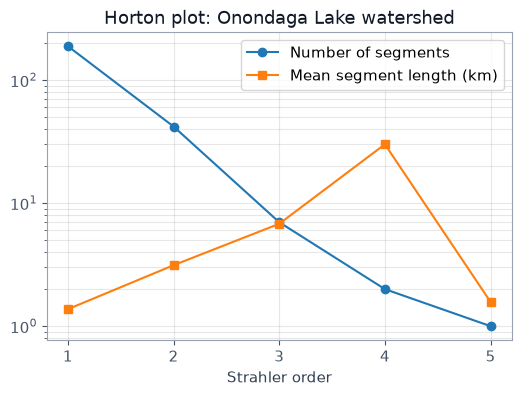

In [11]:
# Stream-order statistics for the whole lake watershed (Horton's laws).
ws_ends = segment_ends(in_ws)
rows_ = []
for u in range(1, int(np.nanmax(order[in_ws & streams])) + 1):
    cells = in_ws & streams & (order == u)
    n_u = int((ws_ends & cells).sum())
    len_u = float(np.nansum(step_km[cells]))
    rows_.append({"order": u, "segments": n_u, "total_length_km": len_u, "mean_length_km": len_u / max(n_u, 1)})
horton = pd.DataFrame(rows_).set_index("order")
horton["bifurcation_ratio"] = horton["segments"] / horton["segments"].shift(-1)
display(horton)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(horton.index, horton["segments"], "o-", label="Number of segments")
ax.semilogy(horton.index, horton["mean_length_km"], "s-", label="Mean segment length (km)")
ax.set_xlabel("Strahler order")
ax.set_xticks(horton.index)
ax.set_title("Horton plot: Onondaga Lake watershed")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

**Reading the tables.**

- **Shape.** Every unit has an elongation ratio below 0.7 and a form factor below 0.35, so all are elongated. That is expected where sub-basins follow long, straight through valleys, and it is reinforced by using the longest flow path, which is longer than the straight-line basin length, as $L_b$. Elongated basins deliver runoff over a longer time and tend to have lower, broader flood peaks than compact ones of the same area.
- **Relief.** Relief and relief ratio separate the plateau headwaters from the lake-plain units near Syracuse.
- **Network.** For the whole watershed, segment counts fall roughly geometrically with order and mean segment length rises through order 4, as Horton's laws predict. The single order-5 segment is short because it forms only where the two main creeks meet inside the lake. Bifurcation ratios between 3 and 5 indicate a network that is not strongly controlled by geological structure; values outside that range in individual sub-basins mostly reflect the low segment counts at this resolution.

Indices built on stream counts are unstable in units with only a handful of segments. Treat differences between small sub-basins with caution.

## Hypsometric analysis

The **hypsometric curve** plots the share of basin area lying above each relative height. Its integral,

$$
HI = \frac{\bar z - z_{min}}{z_{max} - z_{min}},
$$

summarises how much of the original land mass remains. In Strahler's interpretation, $HI > 0.6$ indicates a youthful, actively eroding basin, $0.35$ to $0.6$ a mature one, and $HI < 0.35$ a subdued, old-stage landscape. In glaciated terrain such as this, the curve also reflects valley filling by glacial sediment.

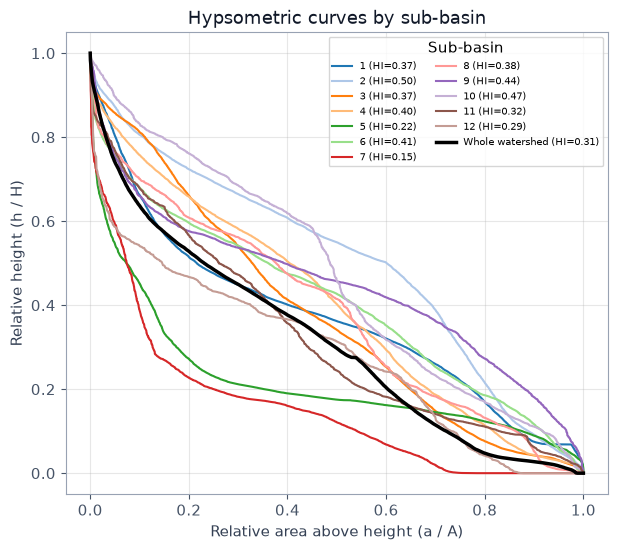

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
cmap = plt.get_cmap("tab20")
hi = {}
for k, i in enumerate(analysis_ids):
    z = np.sort(dem[sub == i])[::-1]  # elevations from high to low
    rel_h = (z - z.min()) / (z.max() - z.min())  # relative height h/H
    rel_a = np.arange(1, z.size + 1) / z.size  # relative area a/A above that height
    hi[i] = float((z.mean() - z.min()) / (z.max() - z.min()))
    ax.plot(rel_a, rel_h, color=cmap(k % 20), label=f"{i} (HI={hi[i]:.2f})")
z = np.sort(dem[in_ws])[::-1]
ax.plot(np.arange(1, z.size + 1) / z.size, (z - z.min()) / (z.max() - z.min()), color="black", linewidth=2.5,
        label=f"Whole watershed (HI={(z.mean() - z.min()) / (z.max() - z.min()):.2f})")
ax.set_xlabel("Relative area above height (a / A)")
ax.set_ylabel("Relative height (h / H)")
ax.set_title("Hypsometric curves by sub-basin")
ax.legend(fontsize=7, ncol=2, title="Sub-basin")
ax.grid(alpha=0.3)
plt.show()

morph["hypsometric_integral"] = pd.Series(hi)

**Reading the curves.** The whole watershed has a hypsometric integral near 0.3, and no sub-basin exceeds 0.5. Most of the area lies low relative to the relief, the signature of broad valley floors and a wide lake plain beneath a narrow band of plateau upland. The lowest integrals belong to the lake-plain units around Syracuse; the highest belong to the plateau headwater units. In this glaciated landscape the low values record valley widening and filling by ice and sediment more than long fluvial erosion.

## Terrain and wetness by sub-basin

Four terrain layers describe how each sub-basin sheds or holds water:

- **Slope** in degrees.
- **Topographic wetness index**, $\mathrm{TWI} = \ln(a / \tan\beta)$, high where a large upslope area meets a gentle slope.
- **Landforms** from the topographic position index at two scales.
- **Height above the nearest stream** (HAND), a simple indicator of valley-bottom land. Cells within a few metres of the channel are candidate floodplain; this layer is the starting point of the flood capstone.

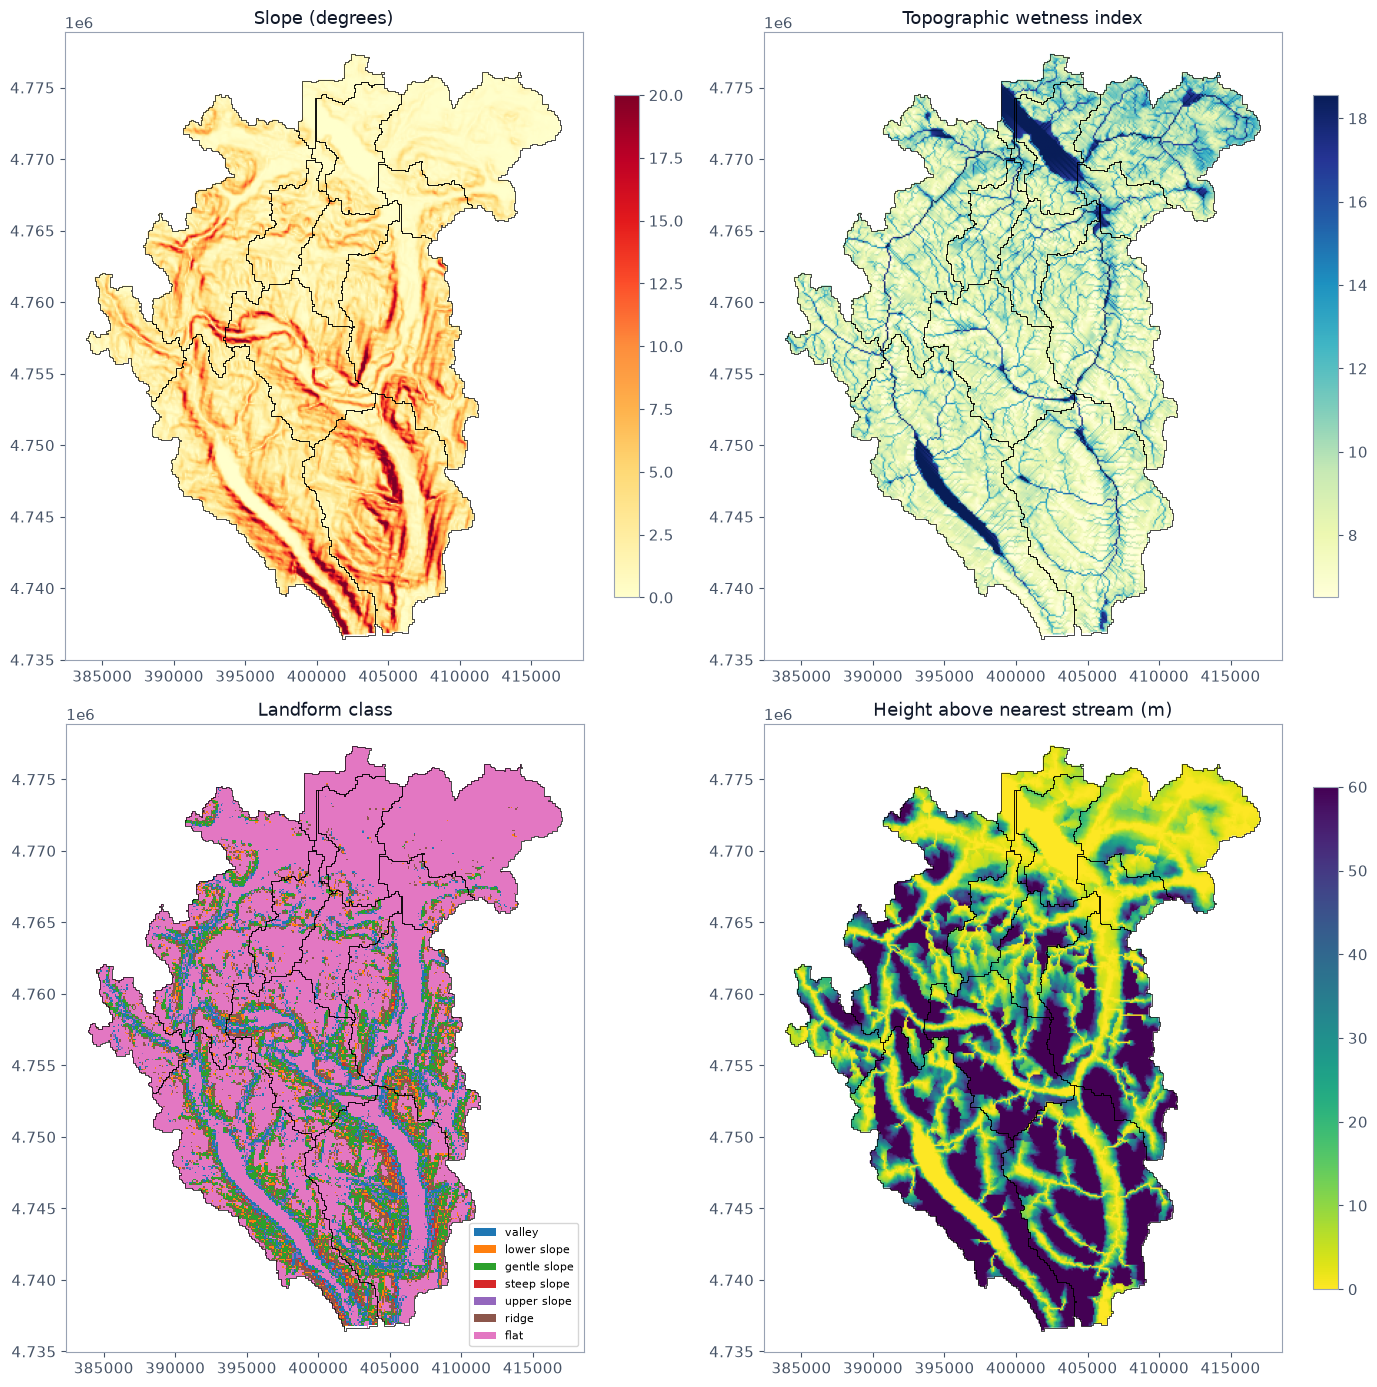

,percent of watershed
valley,8.30
lower slope,3.16
gentle slope,12.06
steep slope,0.63
upper slope,2.99
ridge,8.86
flat,63.95


In [13]:
SLOPE = OUT / "slope_deg.tif"
TWI = OUT / "twi.tif"
LANDFORM = OUT / "landforms.tif"
HAND = OUT / "height_above_stream.tif"

slope(DEM, SLOPE, units="degrees", overwrite=True)
wetness_index(DEM_COND, TWI, method="dinf", overwrite=True)
landform_info = landform_classification(DEM, LANDFORM, small_window=3, large_window=21, overwrite=True)
elevation_above_stream(DEM_COND, STREAMS, D8, HAND, overwrite=True)

slope_deg, _, _ = dp.read_band(SLOPE)
twi, _, _ = dp.read_band(TWI)
landform, _, _ = dp.read_band(LANDFORM)
hand, _, _ = dp.read_band(HAND)

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
panels = [
    (slope_deg, "Slope (degrees)", "YlOrRd", dict(vmin=0, vmax=20)),
    (twi, "Topographic wetness index", "YlGnBu", dict(vmin=np.nanpercentile(twi, 2), vmax=np.nanpercentile(twi, 98))),
    (landform, "Landform class", "tab10", dict(interpolation="nearest", vmin=0.5, vmax=10.5)),
    (hand, "Height above nearest stream (m)", "viridis_r", dict(vmin=0, vmax=60)),
]
for ax, (arr, title, cm, kw) in zip(axes.ravel(), panels):
    im = ax.imshow(np.where(in_ws, arr, np.nan), cmap=cm, extent=EXTENT, **kw)
    sub_gdf.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_xlim(xmin - 1500, xmax + 1500)
    ax.set_ylim(ymin - 1500, ymax + 1500)
    ax.set_title(title)
    if title == "Landform class":
        classes = landform_info["classes"]  # {code: name} returned by landform_classification
        handles = [plt.Rectangle((0, 0), 1, 1, fc=plt.get_cmap("tab10")((k - 0.5) / 10)) for k in classes]
        ax.legend(handles, [v.replace("_", " ") for v in classes.values()], loc="lower right", fontsize=8)
    else:
        plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

# Share of the watershed in each landform class.
lf_share = pd.Series({name.replace("_", " "): 100 * np.mean(landform[in_ws] == code)
                      for code, name in landform_info["classes"].items()}, name="percent of watershed")
display(lf_share.to_frame())

In [14]:
# Zonal summaries on the sub-basin raster.
terrain_rows = []
for i in analysis_ids:
    m = sub == i
    s = slope_deg[m]
    terrain_rows.append(
        {
            "sub_id": i,
            "mean_elev_m": np.nanmean(dem[m]),
            "mean_slope_deg": np.nanmean(s),
            "pct_slope_gt_8deg": 100 * np.nanmean(s > 8),
            "mean_twi": np.nanmean(twi[m]),
            "pct_hand_lt_2m": 100 * np.nanmean(hand[m] < 2),
        }
    )
terrain = pd.DataFrame(terrain_rows).set_index("sub_id")
morph = morph.join(terrain)
display(terrain)

,mean_elev_m,mean_slope_deg,pct_slope_gt_8deg,mean_twi,pct_hand_lt_2m
sub_id,,,,,
1,350.23,5.16,19.19,9.42,15.64
2,362.65,6.27,29.73,8.69,9.92
3,206.52,3.34,7.05,9.31,14.75
4,252.21,4.44,14.89,9.02,12.66
5,128.41,0.89,0.09,10.82,37.23
6,270.86,4.72,15.74,8.86,11.16
7,125.37,1.08,0.15,12.58,47.18
8,225.37,2.54,1.89,9.48,16.39
9,284.05,3.11,4.81,9.11,12.27


The share of land within 2 m of the channel (`pct_hand_lt_2m`) is highest in the units on the lake plain and along the wide valley floors. Those are the same units with low mean slope and high wetness index. Steep land (`pct_slope_gt_8deg`) is concentrated in the plateau headwaters.

## Hydrologic response

How quickly does a sub-basin respond to a storm? A first estimate is the **time of concentration**, the travel time from the most distant point to the outlet. The Kirpich (1940) formula needs only the length and slope of the main flow path:

$$
t_c = 0.0195\; L^{0.77}\; S^{-0.385}
$$

with $t_c$ in minutes, $L$ in metres and $S$ the mean slope of the path (m/m). It was derived for small agricultural basins, so values for large or urban units are indicative only and are best used to **compare** sub-basins.

,flow_path_km,flow_path_slope_pct,tc_kirpich_hr
sub_id,,,
1,27.39,1.30,4.52
2,22.83,1.60,3.63
3,25.10,1.00,4.67
4,23.53,1.29,4.04
5,20.20,0.13,8.61
6,15.30,1.27,2.91
7,10.75,0.62,2.92
8,13.72,2.02,2.24
9,9.96,0.61,2.78


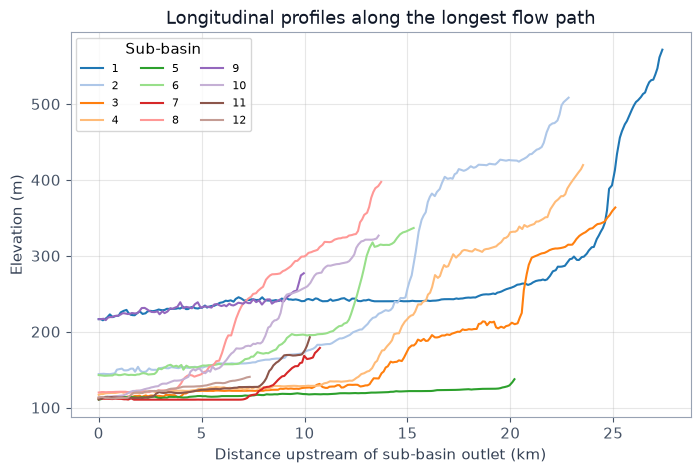

In [15]:
resp = []
profiles = {}
for i in analysis_ids:
    m = sub == i
    d = np.where(m, flow_len, np.nan)
    r0, c0 = np.unravel_index(np.nanargmax(d), d.shape)  # most distant cell
    # Walk downstream to the sub-basin outlet, recording distance and elevation.
    dist, elev = [0.0], [dem[r0, c0]]
    idx = r0 * dem.shape[1] + c0
    while True:
        r, c = divmod(idx, dem.shape[1])
        if targets[r, c] or recv[idx] < 0:
            break
        dist.append(dist[-1] + step[idx] * CELL)
        idx = recv[idx]
        elev.append(dem[divmod(idx, dem.shape[1])])
    L = dist[-1]
    S = max((elev[0] - elev[-1]) / L, 1e-4)  # mean slope of the main flow path
    tc_min = 0.0195 * L**0.77 * S**-0.385
    profiles[i] = (np.array(dist) / 1000.0, np.array(elev))
    resp.append({"sub_id": i, "flow_path_km": L / 1000.0, "flow_path_slope_pct": 100 * S, "tc_kirpich_hr": tc_min / 60.0})
response = pd.DataFrame(resp).set_index("sub_id")
morph = morph.join(response)
display(response)

fig, ax = plt.subplots(figsize=(8, 5))
for k, i in enumerate(analysis_ids):
    x, y = profiles[i]
    ax.plot(x.max() - x, y, color=cmap(k % 20), label=str(i))  # distance upstream of the outlet
ax.set_xlabel("Distance upstream of sub-basin outlet (km)")
ax.set_ylabel("Elevation (m)")
ax.set_title("Longitudinal profiles along the longest flow path")
ax.legend(title="Sub-basin", ncol=3, fontsize=8)
ax.grid(alpha=0.3)
plt.show()

The profiles show the two-part character of the watershed. Plateau tributaries drop steeply and then flatten abruptly where they reach a through valley; that break in slope is where sediment is deposited and where flood water spreads. Units on the lake plain have short, nearly level profiles.

## Land cover and soils (optional external data)

Runoff depends on what covers the ground as much as on its shape. Two layers complete a characterization, and neither ships with the repository:

| Layer | Expected file (under `Data/03_spatial_analysis/capstone_spatial_analysis/`) | Source |
|---|---|---|
| Land cover | `onondaga/nlcd_landcover.tif` | NLCD (USGS / MRLC) |
| Hydrologic soil group | `onondaga/soil_hydrologic_group.tif` | gSSURGO (USDA NRCS), coded A=1, B=2, C=3, D=4 |

When both files are present, the cell below resamples them to the analysis grid, reports land-cover composition per sub-basin and computes an area-weighted **SCS curve number**. When they are missing, the cell reports that and the notebook continues with terrain-only indicators.

In [16]:
ext = dp.check_external_data(ROOT, ["onondaga_nlcd", "onondaga_hsg"])
HAVE_LANDCOVER = all(p is not None for p in ext.values())

if not HAVE_LANDCOVER:
    missing = [dp.EXTERNAL_DATA[k]["file"] for k, p in ext.items() if p is None]
    print("Optional layers not found, section skipped:")
    for f in missing:
        print(f"  Data/03_spatial_analysis/capstone_spatial_analysis/{f}")
else:
    from geolattice.raster import warp  # resample onto the analysis grid

    def to_grid(src, name):
        """Nearest-neighbour resample of a categorical raster onto the DEM grid."""
        dst = OUT / name
        warp(src, dst, dst_crs=dp.ONONDAGA_CRS, resample="near", xRes=CELL, yRes=CELL,
             outputBounds=(EXTENT[0], EXTENT[2], EXTENT[1], EXTENT[3]), overwrite=True)
        return dp.read_band(dst)[0]

    nlcd = to_grid(ext["onondaga_nlcd"], "nlcd_grid.tif")
    hsg = to_grid(ext["onondaga_hsg"], "hsg_grid.tif")

    # NLCD classes grouped into broad covers.
    groups = {"water_wetland": [11, 90, 95], "developed": [21, 22, 23, 24], "forest": [41, 42, 43],
              "shrub_grass": [52, 71], "pasture": [81], "cropland": [82], "barren": [31]}
    # Curve numbers (antecedent condition II) by cover group and soil group A-D.
    cn_table = {"water_wetland": (98, 98, 98, 98), "developed": (77, 85, 90, 92), "forest": (36, 60, 73, 79),
                "shrub_grass": (39, 61, 74, 80), "pasture": (49, 69, 79, 84), "cropland": (67, 78, 85, 89),
                "barren": (77, 86, 91, 94)}
    cn = np.full(dem.shape, np.nan)
    for g, codes in groups.items():
        for s in (1, 2, 3, 4):
            cn[np.isin(nlcd, codes) & (hsg == s)] = cn_table[g][s - 1]

    lc_rows = []
    for i in analysis_ids:
        m = sub == i
        row = {"sub_id": i, "curve_number": np.nanmean(cn[m])}
        for g, codes in groups.items():
            row[f"pct_{g}"] = 100 * np.mean(np.isin(nlcd[m], codes))
        lc_rows.append(row)
    landcover = pd.DataFrame(lc_rows).set_index("sub_id")
    morph = morph.join(landcover)
    display(landcover)

Optional layers not found, section skipped:
  Data/03_spatial_analysis/capstone_spatial_analysis/onondaga/nlcd_landcover.tif
  Data/03_spatial_analysis/capstone_spatial_analysis/onondaga/soil_hydrologic_group.tif


## Sub-basin prioritisation

Morphometric prioritisation ranks sub-basins by how strongly their form favours rapid runoff and erosion. The usual scheme is a **compound ranking**:

- **Linear and relief parameters** (drainage density, stream frequency, bifurcation ratio, drainage texture, relief ratio, mean slope) are positively related to runoff and erosion: the largest value receives rank 1.
- **Shape parameters** (form factor, circularity ratio, elongation ratio) are ranked the other way, following the convention of Biswas, Sudhakar and Desai (1999): the smallest value receives rank 1.

The **compound value** is the mean of the ranks; the lowest compound value is the highest priority. The method is a screening tool. It says where terrain form warrants a closer look, not where erosion is actually occurring.

In [17]:
direct = ["drainage_density", "stream_frequency", "bifurcation_ratio", "drainage_texture", "relief_ratio", "mean_slope_deg"]
inverse = ["form_factor", "circularity_ratio", "elongation_ratio"]
if HAVE_LANDCOVER:
    direct.append("curve_number")  # more runoff-prone cover and soil -> higher priority

ranks = pd.DataFrame(index=morph.index)
for col in direct:
    ranks[col] = morph[col].rank(ascending=False, na_option="bottom")  # largest value -> rank 1
for col in inverse:
    ranks[col] = morph[col].rank(ascending=True, na_option="bottom")  # smallest value -> rank 1

morph["compound_value"] = ranks.mean(axis=1)
morph["priority_rank"] = morph["compound_value"].rank(method="min").astype(int)
morph["priority_class"] = pd.qcut(morph["compound_value"].rank(method="first"), 3, labels=["High", "Medium", "Low"])

display(ranks.assign(compound_value=morph["compound_value"], priority=morph["priority_class"]).sort_values("compound_value"))

,drainage_density,stream_frequency,bifurcation_ratio,drainage_texture,relief_ratio,mean_slope_deg,form_factor,circularity_ratio,elongation_ratio,compound_value,priority
sub_id,,,,,,,,,,,
3,7.0,7.0,1.0,5.0,8.0,5.0,3.0,1.0,3.0,4.44,High
8,4.0,4.0,10.5,9.0,2.0,7.0,2.0,5.0,2.0,5.06,High
4,6.0,8.0,5.5,3.0,6.0,4.0,4.0,7.0,4.0,5.28,High
1,11.0,10.0,2.0,4.0,7.0,2.0,5.0,3.0,5.0,5.44,High
10,1.0,12.0,3.5,11.0,4.0,8.0,1.0,8.0,1.0,5.50,Medium
6,8.0,2.0,5.5,2.0,1.0,3.0,11.0,11.0,11.0,6.06,Medium
9,5.0,1.0,12.0,7.0,5.0,6.0,10.0,4.0,10.0,6.67,Medium
2,10.0,9.0,9.0,1.0,3.0,1.0,9.0,12.0,9.0,7.00,Medium
11,2.0,5.0,3.5,10.0,10.0,9.0,7.0,10.0,7.0,7.06,Low


### Sensitivity of the ranking

A ranking built from nine equally weighted parameters can hinge on any one of them. Two checks:

1. **Leave one parameter out.** Recompute the compound value nine times, each time without one parameter, and record the range of ranks each sub-basin receives.
2. **Stream threshold.** Recompute drainage density with thresholds of 0.5 and 2 km² and compare the resulting order of sub-basins.

In [18]:
# 1. Leave-one-parameter-out rank range.
loo = pd.DataFrame({col: ranks.drop(columns=col).mean(axis=1).rank(method="min") for col in ranks.columns})
stability = pd.DataFrame(
    {
        "priority_rank": morph["priority_rank"],
        "best_rank": loo.min(axis=1).astype(int),
        "worst_rank": loo.max(axis=1).astype(int),
        "priority_class": morph["priority_class"],
    }
).sort_values("priority_rank")
stability["rank_range"] = stability.worst_rank - stability.best_rank
display(stability)

# 2. Drainage density under different stream thresholds.
dd = pd.DataFrame(index=analysis_ids)
for thr in [0.5, 1.0, 2.0]:
    st_mask = fa * CELL_KM2 >= thr
    dd[f"Dd_{thr:g}km2"] = [np.nansum(step_km[(sub == i) & st_mask]) / area_km2[i] for i in analysis_ids]
print("Spearman rank correlation of drainage density across thresholds:")
display(dd.corr(method="spearman"))

,priority_rank,best_rank,worst_rank,priority_class,rank_range
sub_id,,,,,
3,1,1,2,High,1
8,2,1,5,High,4
4,3,2,4,High,2
1,4,2,6,High,4
10,5,2,6,Medium,4
6,6,2,7,Medium,5
9,7,6,9,Medium,3
2,8,7,9,Medium,2
11,9,6,9,Low,3


Spearman rank correlation of drainage density across thresholds:


,Dd_0.5km2,Dd_1km2,Dd_2km2
Dd_0.5km2,1.00,0.42,0.57
Dd_1km2,0.42,1.00,0.62
Dd_2km2,0.57,0.62,1.00


**Reading the sensitivity checks.** Sub-basins whose rank moves by only a few places when a parameter is dropped are robustly placed. In this run the top-ranked unit keeps its rank in every case and the low-priority units move by at most three places. Units in the middle of the table move by four or five places, so the boundary between the high and medium classes is not firm. The rank correlations of drainage density across thresholds are only moderate (about 0.6 to 0.7): the ordering of sub-basins by drainage density changes noticeably with the definition of a stream. Both checks say the same thing: read the classes as broad groups, not as an exact order.

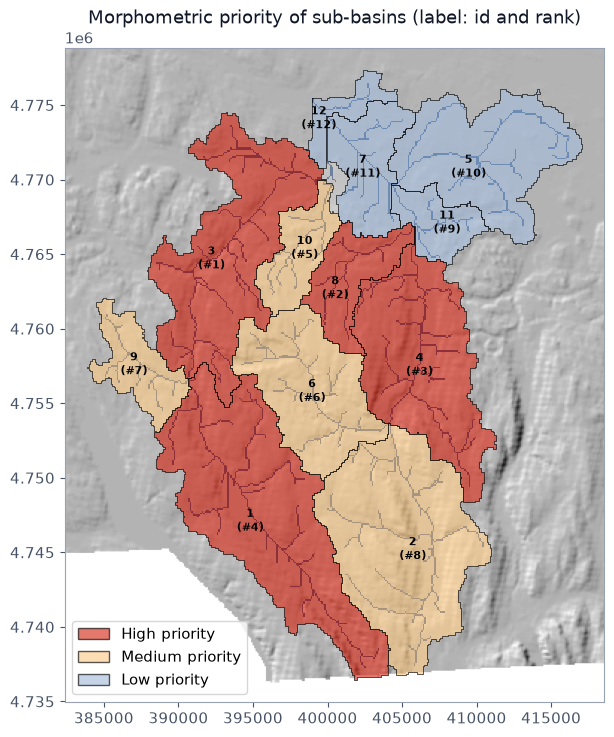

In [19]:
# Priority map.
plot_gdf = sub_gdf.merge(morph.reset_index(), on="sub_id", how="left")
colors = {"High": "#d7301f", "Medium": "#fdcc8a", "Low": "#a6bddb"}

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(hs, cmap="gray", extent=EXTENT)
for cls, col in colors.items():
    part = plot_gdf[plot_gdf.priority_class == cls]
    if len(part):
        part.plot(ax=ax, color=col, alpha=0.65, edgecolor="black", linewidth=0.7)
plot_gdf[plot_gdf.priority_class.isna()].plot(ax=ax, color="lightgrey", alpha=0.5, edgecolor="black", linewidth=0.4)
ax.imshow(np.where(streams & in_ws, 1.0, np.nan), cmap="Blues", extent=EXTENT, vmin=0, vmax=1, interpolation="nearest")
for _, row in plot_gdf.dropna(subset=["priority_rank"]).iterrows():
    p = row.geometry.representative_point()
    ax.text(p.x, p.y, f"{row.sub_id}\n(#{int(row.priority_rank)})", ha="center", va="center", fontsize=8, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="black", alpha=0.65) for c in colors.values()]
ax.legend(handles, [f"{k} priority" for k in colors], loc="lower left")
ax.set_xlim(xmin - 1500, xmax + 1500)
ax.set_ylim(ymin - 1500, ymax + 1500)
ax.set_title("Morphometric priority of sub-basins (label: id and rank)")
plt.show()

**Reading the map.** The high-priority units form a band across the middle of the watershed, where plateau tributaries drop into the valleys: they combine high drainage density or strong branching with elongated, irregular outlines. The lake-plain units in the north rank low on every relief parameter. Note that the steepest headwater unit in the south-east ranks low overall, because its compact outline scores poorly on the three shape parameters and outweighs its high relief and slope. That is a property of equal-weight compound ranking, and a reason to read the result together with the slope and relief columns of the table, not in place of them.

## Outputs and watershed report card

Everything a later study needs is written to one folder: the hydrology rasters, a GeoPackage of sub-basins with every index as an attribute, and a CSV of the same table.

In [20]:
# Sub-basin polygons with all indices.
out_gdf = sub_gdf.merge(morph.reset_index(), on="sub_id", how="inner")
out_gdf["priority_class"] = out_gdf["priority_class"].astype(str)
GPKG = OUT / "onondaga_subbasins_morphometry.gpkg"
out_gdf.to_file(GPKG, layer="subbasins", driver="GPKG")
gpd.GeoDataFrame(outlets.drop(columns=["x", "y"]), geometry=gpd.points_from_xy(outlets.x_snap, outlets.y_snap),
                 crs=dp.ONONDAGA_CRS).to_file(GPKG, layer="outlets", driver="GPKG")
morph.to_csv(OUT / "onondaga_subbasins_morphometry.csv")

# Whole-watershed summary.
lake_target = np.zeros(dem.shape, dtype=bool)
lake_target[dp.xy_to_rowcol(*lake_xy, GT)] = True  # the lake-outlet cell
lfp_ws_km = float(np.nanmax(dp.flow_distance_to_targets(D8, DEM_COND, lake_target)[in_ws]) / 1000.0)
A_ws = in_ws.sum() * CELL_KM2
L_ws = float(np.nansum(step_km[in_ws & streams]))
z_ws = dem[in_ws]
card = pd.Series(
    {
        "Area (km2)": A_ws,
        "Published area (km2)": 738.0,
        "Elevation range (m)": f"{np.nanmin(z_ws):.0f} to {np.nanmax(z_ws):.0f}",
        "Mean slope (degrees)": float(np.nanmean(slope_deg[in_ws])),
        "Hypsometric integral": float((z_ws.mean() - z_ws.min()) / (z_ws.max() - z_ws.min())),
        "Stream length (km)": L_ws,
        "Drainage density (km/km2)": L_ws / A_ws,
        "Highest Strahler order": int(np.nanmax(order[in_ws & streams])),
        "Longest flow path (km)": lfp_ws_km,
        "Land within 2 m of a stream (%)": float(100 * np.nanmean(hand[in_ws] < 2)),
        "Sub-basins analysed": len(analysis_ids),
        "High-priority sub-basins": ", ".join(str(i) for i in morph.index[morph.priority_class == "High"]),
    },
    name="Onondaga Lake watershed",
)
display(card.to_frame())

print("Files written:")
for p in sorted(OUT.glob("*")):
    if p.is_file():
        print(f"  {p.name:45s} {p.stat().st_size / 1024:9.1f} KB")

,Onondaga Lake watershed
Area (km2),735.88
Published area (km2),738.0
Elevation range (m),110 to 581
Mean slope (degrees),3.88
Hypsometric integral,0.31
Stream length (km),500.45
Drainage density (km/km2),0.68
Highest Strahler order,5
Longest flow path (km),54.89
Land within 2 m of a stream (%),18.52


Files written:
  d8_flow_accumulation.tif                         1106.1 KB
  d8_pointer.tif                                   1106.1 KB
  dem_conditioned.tif                              1106.1 KB
  dinf_sca.tif                                     1106.1 KB
  flow_length_to_subbasin_outlet.tif               1106.1 KB
  height_above_stream.tif                          1106.1 KB
  hillshade.tif                                     276.5 KB
  landforms.tif                                    1106.1 KB
  onondaga_subbasins_morphometry.csv                  6.0 KB
  onondaga_subbasins_morphometry.gpkg               184.0 KB
  slope_deg.tif                                    1105.0 KB
  strahler_order.tif                               1106.1 KB
  streams.tif                                      1106.1 KB
  subbasins.tif                                    1106.1 KB
  subbasins_raw.gpkg                                180.0 KB
  subbasins_raw.tif                                1106.1 KB
  twi.tif

## Limitations

- **Resolution.** A 100 m DEM cannot resolve small urban catchments or channels narrower than a cell. Harbor Brook is the clear failure in the validation table. Repeating the analysis with the 10 m USGS 3DEP DEM would improve small-basin divides and raise drainage density.
- **Engineered drainage.** Storm sewers, culverts and the Onondaga Creek flood-control dam are not represented. In Syracuse the real drainage network departs from the terrain surface.
- **County clip.** The DEM stops at the county line. The lake watershed fits almost entirely inside it, but any study of the Seneca or Oneida rivers would need a wider DEM.
- **Threshold dependence.** Drainage density, stream frequency and everything derived from them depend on the 1 km² stream threshold.
- **Lakes.** Onondaga and Otisco lakes are treated as flat land that drains across its surface. Flow lengths across them are geometric, not hydraulic.
- **Kirpich times.** The formula is outside its calibration range for the large units; use the values to compare sub-basins, not as design numbers.
- **Prioritisation.** Compound ranking weights all parameters equally and uses terrain form only. It screens for where to look; it does not measure erosion or runoff.

## Where to go next

| If you need... | Open |
|---|---|
| Flood susceptibility built on the layers written here | [`03_08_01_flood_susceptibility_mapping.ipynb`](03_08_01_flood_susceptibility_mapping.ipynb) |
| The flow-routing algorithms in detail | [`03_02_03_hydrology_modeling.ipynb`](../03_02_digital_terrain_modeling/03_02_03_hydrology_modeling.ipynb) |
| Terrain derivatives and landforms | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |
| Weighted and fuzzy combination of criteria | Module `03_04_mcsm` |

### References

1. Barnes, R., Lehman, C., Mulla, D. (2014). Priority-flood: an optimal depression-filling and watershed-labeling algorithm for digital elevation models. *Computers & Geosciences*, 62, 117-127.
2. Biswas, S., Sudhakar, S., Desai, V. R. (1999). Prioritisation of subwatersheds based on morphometric analysis of drainage basin: a remote sensing and GIS approach. *Journal of the Indian Society of Remote Sensing*, 27, 155-166.
3. Horton, R. E. (1945). Erosional development of streams and their drainage basins. *Geological Society of America Bulletin*, 56, 275-370.
4. Kirpich, Z. P. (1940). Time of concentration of small agricultural watersheds. *Civil Engineering*, 10(6), 362.
5. Strahler, A. N. (1952). Hypsometric (area-altitude) analysis of erosional topography. *Geological Society of America Bulletin*, 63, 1117-1142.
6. Strahler, A. N. (1957). Quantitative analysis of watershed geomorphology. *Transactions of the American Geophysical Union*, 38, 913-920.